# 00 · Dataset interview playbook


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

import lightgbm as lgb
from sklearn.model_selection import KFold, StratifiedKFold, GroupKFold, TimeSeriesSplit, cross_validate
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import RidgeCV, LogisticRegressionCV
from sklearn.dummy import DummyRegressor, DummyClassifier

ISSUES = []                     # running list of findings, to read out on the check-in call / put in the deck
def issue(msg):
    ISSUES.append(msg); print("ISSUE:", msg)

## 0. Config: the only cell you need to edit

In [2]:
DATA_PATH = None                 # e.g. "data/train.csv"; None = build the messy demo dataset
TARGET = "price"
TASK = "regression"              # "regression" or "classification"
ID_COLS = ["listing_id"]         # identifiers: never used as features
TIME_COL = "listing_date"        # None if not time-ordered
GROUP_COL = None                 # e.g. "customer_id" if rows come in groups
SPLIT = "kfold"                  # "kfold" | "group" | "time": how the model will be USED decides this
N_SPLITS = 5

In [3]:
def make_demo():
    # California housing with realistic problems planted in it.
    from sklearn.datasets import fetch_california_housing
    d = fetch_california_housing(as_frame=True).frame.rename(columns={"MedHouseVal": "price"})
    n = len(d)
    d.insert(0, "listing_id", np.arange(100000, 100000 + n))
    d.insert(1, "listing_date", pd.Timestamp("2019-01-01") + pd.to_timedelta(rng.integers(0, 5 * 365, n), unit="D"))
    d["region"] = np.where(d["Longitude"] < -121, "north_coast", np.where(d["Latitude"] > 35, "central", "south"))
    d.loc[rng.random(n) < 0.04, "HouseAge"] = np.nan                       # missing values
    d.loc[rng.random(n) < 0.005, "AveRooms"] = -999                        # sentinel for "unknown"
    d["appraisal_value"] = d["price"] * 1.03 + rng.normal(0, 0.05, n)      # leaky: assessed AFTER the sale
    d["data_source"] = "mls_feed"                                          # constant column
    d = pd.concat([d, d.sample(150, random_state=SEED)], ignore_index=True) # duplicated rows
    return d

df = pd.read_csv(DATA_PATH) if DATA_PATH else make_demo()
if TIME_COL and not np.issubdtype(df[TIME_COL].dtype, np.datetime64):
    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
print(df.shape)
df.head()

(20790, 14)


,listing_id,listing_date,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price,region,appraisal_value,data_source
0,100000,2019-06-12,8.3252,41.0,6.9841,1.0238,322.0,2.5556,37.88,-122.23,4.526,north_coast,4.5313,mls_feed
1,100001,2022-11-13,8.3014,21.0,6.2381,0.9719,2401.0,2.1098,37.86,-122.22,3.585,north_coast,3.7013,mls_feed
2,100002,2022-04-09,7.2574,52.0,8.2881,1.0734,496.0,2.8023,37.85,-122.24,3.521,north_coast,3.7353,mls_feed
3,100003,2021-03-11,5.6431,52.0,5.8174,1.0731,558.0,2.5479,37.85,-122.25,3.413,north_coast,3.5314,mls_feed
4,100004,2021-03-01,3.8462,52.0,6.2819,1.0811,565.0,2.1815,37.85,-122.25,3.422,north_coast,3.6728,mls_feed


## 1. First look

In [4]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 20790 entries, 0 to 20789
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   listing_id       20790 non-null  int64         
 1   listing_date     20790 non-null  datetime64[us]
 2   MedInc           20790 non-null  float64       
 3   HouseAge         19950 non-null  float64       
 4   AveRooms         20790 non-null  float64       
 5   AveBedrms        20790 non-null  float64       
 6   Population       20790 non-null  float64       
 7   AveOccup         20790 non-null  float64       
 8   Latitude         20790 non-null  float64       
 9   Longitude        20790 non-null  float64       
 10  price            20790 non-null  float64       
 11  region           20790 non-null  str           
 12  appraisal_value  20790 non-null  float64       
 13  data_source      20790 non-null  str           
dtypes: datetime64[us](1), float64(10), int64(1), str(

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
listing_id,20790.0,NaN,NaN,NaN,110321.2297,100000.0,105157.25,110318.5,115480.75,120639.0,5959.5941
listing_date,20790,NaN,NaN,NaN,2021-06-23 14:51:34.025974,2019-01-01 00:00:00,2020-03-26 00:00:00,2021-06-22 00:00:00,2022-09-20 00:00:00,2023-12-30 00:00:00,NaN
MedInc,20790.0,NaN,NaN,NaN,3.8699,0.4999,2.5639,3.5341,4.7419,15.0001,1.8995
HouseAge,19950.0,NaN,NaN,NaN,28.651,1.0,18.0,29.0,37.0,52.0,12.5765
AveRooms,20790.0,NaN,NaN,NaN,-0.1765,-999.0,4.4252,5.2198,6.0466,141.9091,74.8603
AveBedrms,20790.0,NaN,NaN,NaN,1.0964,0.3333,1.0061,1.0487,1.0995,34.0667,0.4724
Population,20790.0,NaN,NaN,NaN,1425.9192,3.0,787.0,1166.0,1726.75,35682.0,1132.1618
AveOccup,20790.0,NaN,NaN,NaN,3.0699,0.6923,2.4304,2.8189,3.2824,1243.3333,10.3487
Latitude,20790.0,NaN,NaN,NaN,35.6306,32.54,33.93,34.26,37.71,41.95,2.1358
Longitude,20790.0,NaN,NaN,NaN,-119.569,-124.35,-121.8,-118.49,-118.01,-114.31,2.0034


## 2. Data-quality report
One row per column. Read the flags column first; `top_share` catches caps and sentinel codes (a single value covering an odd share of rows).

In [6]:
SENTINELS = [-999, -99, -1, 999, 9999, 99999]

def sentinel_values(s, min_share=0.002):
    # Common "unknown" codes that appear suspiciously often. A heuristic: a real value of 999 is possible, so check.
    if not (pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)):
        return []
    share = s[s.isin(SENTINELS)].value_counts() / len(s)
    return [float(v) for v, sh in share.items() if sh >= min_share]

def quality_report(d):
    rows = []
    for c in d.columns:
        s = d[c]
        vc = s.value_counts(dropna=True)
        num = pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
        r = {"column": c, "dtype": str(s.dtype), "missing_%": 100 * s.isna().mean(), "n_unique": s.nunique(),
             "top_value": vc.index[0] if len(vc) else None, "top_share_%": 100 * vc.iloc[0] / len(s) if len(vc) else 0,
             "min": s.min() if num else None, "max": s.max() if num else None}
        flags = []
        if r["n_unique"] <= 1: flags.append("constant")
        if r["missing_%"] > 0: flags.append("missing")
        if sentinel_values(s): flags.append(f"sentinel? {sentinel_values(s)}")
        if r["n_unique"] == len(s) and c != TARGET: flags.append("unique per row (ID?)")
        if num and r["top_share_%"] > 3 and vc.index[0] in (s.min(), s.max()): flags.append("piles up at min/max (cap?)")
        r["flags"] = ", ".join(flags)
        rows.append(r)
    return pd.DataFrame(rows).set_index("column")

qr = quality_report(df)
qr

,dtype,missing_%,n_unique,top_value,top_share_%,min,max,flags
column,,,,,,,,
listing_id,int64,0.0000,20640,100290,0.0096,100000.0000,120639.0000,
listing_date,datetime64[us],0.0000,1825,2020-06-03 00:00:00,0.1154,NaN,NaN,
MedInc,float64,0.0000,12928,15.0001,0.2405,0.4999,15.0001,
HouseAge,float64,4.0404,52,52.0,5.8874,1.0000,52.0000,"missing, piles up at min/max (cap?)"
AveRooms,float64,0.0000,19292,-999.0,0.5580,-999.0000,141.9091,sentinel? [-999.0]
AveBedrms,float64,0.0000,14233,1.0,1.3853,0.3333,34.0667,
Population,float64,0.0000,3888,891.0,0.1203,3.0000,35682.0000,
AveOccup,float64,0.0000,18841,3.0,0.1732,0.6923,1243.3333,
Latitude,float64,0.0000,862,34.06,1.1833,32.5400,41.9500,


In [7]:
for c, f in qr["flags"].items():
    if f: issue(f"`{c}`: {f}")

n_dup = df.duplicated().sum()
if n_dup: issue(f"{n_dup} fully duplicated rows")
for c in ID_COLS:
    n_dup_id = df[c].duplicated().sum()
    if n_dup_id: issue(f"{n_dup_id} repeated values of ID column `{c}`")

ISSUE: `HouseAge`: missing, piles up at min/max (cap?)
ISSUE: `AveRooms`: sentinel? [-999.0]
ISSUE: `price`: piles up at min/max (cap?)
ISSUE: `data_source`: constant
ISSUE: 150 fully duplicated rows
ISSUE: 150 repeated values of ID column `listing_id`


## 3. The target
Shape (skew → log/MAE?), caps, outliers, and for classification the class balance.

skew 0.98 | share at max value 4.7% | missing 0


ISSUE: target is capped: 4.7% of rows sit exactly at the max (5.000)


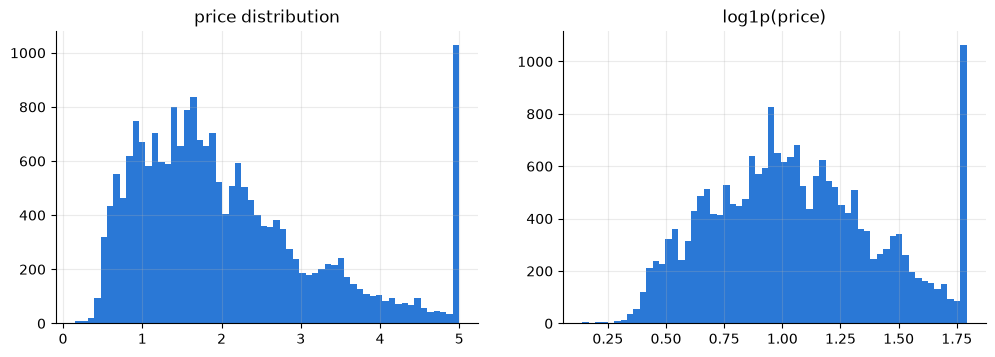

In [8]:
y_raw = df[TARGET]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
if TASK == "regression":
    axes[0].hist(y_raw.dropna(), bins=60, color=PALETTE[0]); axes[0].set_title(f"{TARGET} distribution")
    axes[1].hist(np.log1p(y_raw.clip(lower=0)).dropna(), bins=60, color=PALETTE[0]); axes[1].set_title(f"log1p({TARGET})")
    at_max = (y_raw == y_raw.max()).mean()
    print(f"skew {y_raw.skew():.2f} | share at max value {at_max:.1%} | missing {y_raw.isna().sum()}")
    if at_max > 0.01: issue(f"target is capped: {at_max:.1%} of rows sit exactly at the max ({y_raw.max():.3f})")
else:
    y_raw.value_counts(normalize=True).plot.bar(ax=axes[0], color=PALETTE[0]); axes[0].set_title("class balance")
    axes[1].axis("off")
plt.show()

## 4. Time structure (skip if not time-ordered)
Coverage gaps, volume changes and target drift all affect how you should validate.

range 2019-01-01 -> 2023-12-30, empty months: 0


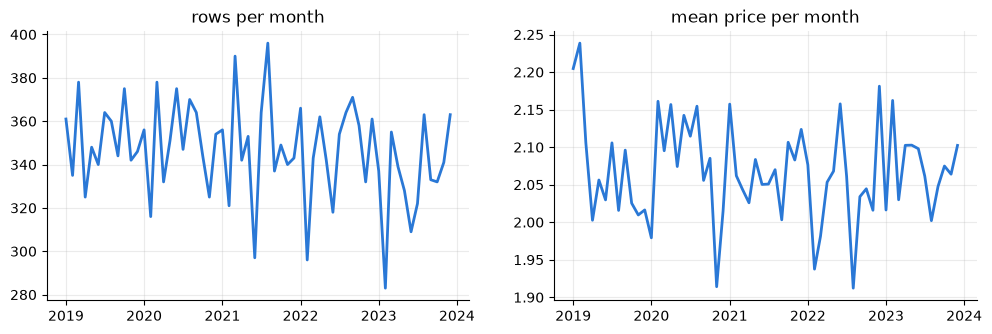

In [9]:
if TIME_COL:
    monthly = df.set_index(TIME_COL).resample("MS")[TARGET].agg(["size", "mean"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    axes[0].plot(monthly.index, monthly["size"], color=PALETTE[0]); axes[0].set_title("rows per month")
    axes[1].plot(monthly.index, monthly["mean"], color=PALETTE[0]); axes[1].set_title(f"mean {TARGET} per month")
    print(f"range {df[TIME_COL].min().date()} -> {df[TIME_COL].max().date()}, empty months: {(monthly['size'] == 0).sum()}")
plt.show()

## 5. Univariate signal scan and leakage check
How much does each feature *alone* tell us about the target? Anything near-perfect is a **leakage suspect** until proven otherwise: ask how and *when* that column is created.

In [10]:
features = [c for c in df.columns if c not in [TARGET, *ID_COLS] and c != TIME_COL]
y_num = df[TARGET] if TASK == "regression" else df[TARGET].astype("category").cat.codes

def single_feature_strength(d, col):
    s = d[col]
    if pd.api.types.is_numeric_dtype(s):
        return abs(s.corr(y_num, method="spearman"))
    # categorical: share of target variance explained by the group means (correlation ratio)
    means = y_num.groupby(s).transform("mean")
    return np.sqrt(means.var() / y_num.var()) if s.nunique() > 1 else 0.0

scan = pd.Series({c: single_feature_strength(df, c) for c in features}, name="strength").sort_values(ascending=False)
for c in ID_COLS + ([TIME_COL] if TIME_COL else []):
    st = abs(pd.Series(df[c]).rank().corr(y_num.rank()))
    if st > 0.1: issue(f"`{c}` is correlated with the target ({st:.2f}): row order / time leakage or drift?")
for c, v in scan.items():
    if v > 0.9: issue(f"`{c}` alone explains almost everything (strength {v:.2f}): leakage suspect")
scan.round(3).to_frame()

ISSUE: `appraisal_value` alone explains almost everything (strength 1.00): leakage suspect


,strength
appraisal_value,0.998
MedInc,0.676
region,0.310
AveRooms,0.261
AveOccup,0.257
Latitude,0.166
AveBedrms,0.124
HouseAge,0.074
Longitude,0.069
Population,0.004


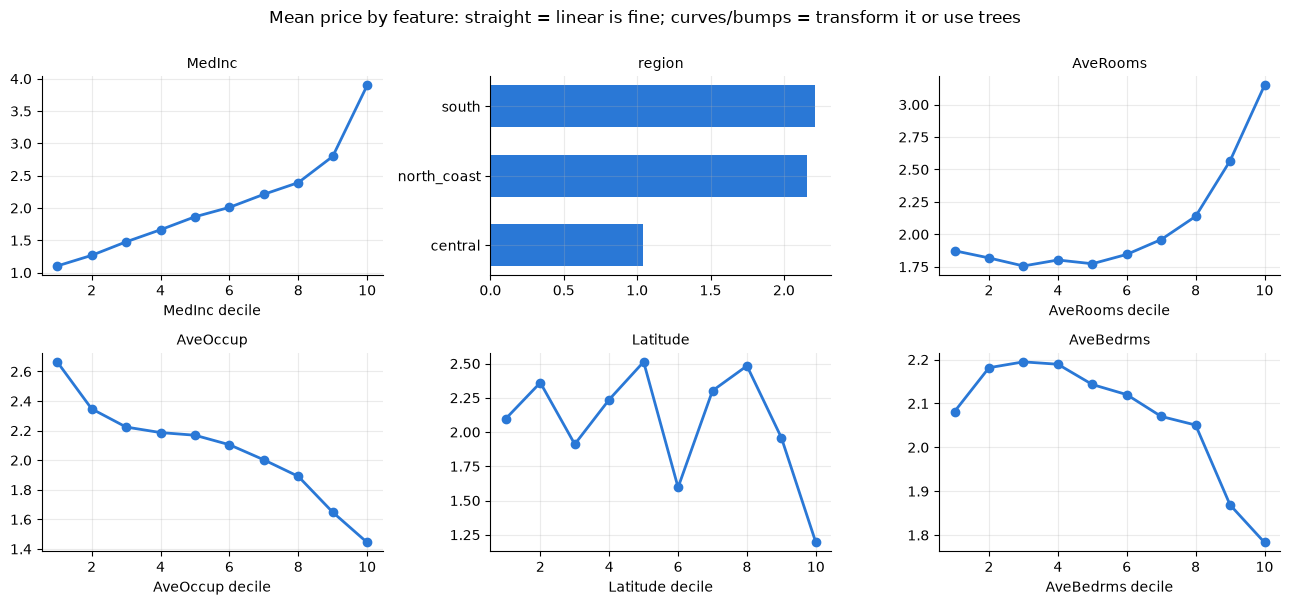

In [11]:
def decile_plot(d, col, ax):
    s = d[col]
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10:
        g = d.groupby(pd.qcut(s, 10, duplicates="drop"), observed=True)[TARGET].mean()
        ax.plot(range(1, len(g) + 1), g.values, "o-", color=PALETTE[0], ms=6); ax.set_xlabel(f"{col} decile")
    else:
        g = d.groupby(s, observed=True)[TARGET].mean().sort_values()
        ax.barh(g.index.astype(str), g.values, color=PALETTE[0], height=0.6)
    ax.set_title(col, fontsize=10)

top = [c for c in scan.index if scan[c] <= 0.9][:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), top):
    decile_plot(df, c, ax)
fig.suptitle(f"Mean {TARGET} by feature: straight = linear is fine; curves/bumps = transform it or use trees", y=1.0)
plt.tight_layout()
plt.show()

## Checkpoint: issues to raise on the call
Bring this list, plus your proposed fix for each and the questions only they can answer:
- What exactly is the target, and how will predictions be used (ranking? point estimates? decisions at a threshold)?
- Which metric do they care about?
- When is each feature known relative to the target? (the leakage question)
- Will the model predict new rows, new entities (groups), or the future?

In [12]:
for i, s in enumerate(ISSUES, 1):
    print(f"{i:2d}. {s}")

 1. `HouseAge`: missing, piles up at min/max (cap?)
 2. `AveRooms`: sentinel? [-999.0]
 3. `price`: piles up at min/max (cap?)
 4. `data_source`: constant
 5. 150 fully duplicated rows
 6. 150 repeated values of ID column `listing_id`
 7. target is capped: 4.7% of rows sit exactly at the max (5.000)
 8. `appraisal_value` alone explains almost everything (strength 1.00): leakage suspect


## 6. Cleaning decisions: explicit and logged
Every change is a sentence in your presentation, so keep them in one place.

In [13]:
CLEANING_LOG = []
def log(msg): CLEANING_LOG.append(msg); print("-", msg)

data = df.copy()
before = len(data); data = data.drop_duplicates()
log(f"dropped {before - len(data)} duplicated rows")
for c in features:
    codes = sentinel_values(data[c])
    if codes:
        k = data[c].isin(codes).sum(); data.loc[data[c].isin(codes), c] = np.nan
        log(f"`{c}`: {k} sentinel values {codes} -> NaN")
const = [c for c in features if data[c].nunique() <= 1]
leaky = [c for c in features if scan[c] > 0.9]
log(f"dropped constant columns {const}")
log(f"dropped leakage suspects {leaky} (confirm on the call!)")
FEATURES = [c for c in features if c not in const + leaky]

if TIME_COL:
    data = data.sort_values(TIME_COL).reset_index(drop=True)
    data["month"] = data[TIME_COL].dt.month          # example of a derived feature
    FEATURES.append("month")
X, y = data[FEATURES], data[TARGET]
print("features:", FEATURES)

- dropped 150 duplicated rows
- `AveRooms`: 112 sentinel values [-999.0] -> NaN
- dropped constant columns ['data_source']
- dropped leakage suspects ['appraisal_value'] (confirm on the call!)
features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'region', 'month']


## 7. Validation, baseline, linear model, boosting: same folds for all
Pick the splitter from **how the model will be used**, not from what scores best.

In [14]:
def get_cv():
    if SPLIT == "time":  return TimeSeriesSplit(N_SPLITS)
    if SPLIT == "group": return GroupKFold(N_SPLITS)
    if TASK == "classification": return StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)
    return KFold(N_SPLITS, shuffle=True, random_state=SEED)
cv = get_cv()
groups = data[GROUP_COL] if SPLIT == "group" else None

linear_prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore", min_frequency=20)), make_column_selector(dtype_exclude="number")),
])
X_lgb = X.copy()
for c in X_lgb.select_dtypes(exclude="number").columns:
    X_lgb[c] = X_lgb[c].astype("category")

if TASK == "regression":
    scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2"}
    models = {"baseline (mean)": (DummyRegressor(), X),
              "Ridge": (make_pipeline(linear_prep, RidgeCV(alphas=np.logspace(-3, 3, 25))), X),
              "LightGBM": (lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                                             colsample_bytree=0.8, random_state=SEED, verbose=-1), X_lgb)}
else:
    scoring = {"logloss": "neg_log_loss", "auc": "roc_auc"}
    models = {"baseline (prior)": (DummyClassifier(strategy="prior"), X),
              "Logistic": (make_pipeline(linear_prep, LogisticRegressionCV(max_iter=3000)), X),
              "LightGBM": (lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                                              colsample_bytree=0.8, random_state=SEED, verbose=-1), X_lgb)}

rows = {}
for name, (m, Xm) in models.items():
    r = cross_validate(m, Xm, y, cv=cv, groups=groups, scoring=scoring)
    rows[name] = {f"{k} mean": abs(r[f"test_{k}"]).mean() for k in scoring} | {f"{k} sd": r[f"test_{k}"].std() for k in scoring}
board = pd.DataFrame(rows).T
board

,rmse mean,r2 mean,rmse sd,r2 sd
baseline (mean),1.1539,3.2610e-05,0.0081,3.4801e-05
Ridge,0.7199,6.1058e-01,0.0071,1.2578e-02
LightGBM,0.4468,8.5008e-01,0.0058,3.1231e-03


Questions to answer from this table (each is a slide sentence):
- How much better than the baseline is the simple model?
- Does boosting beat the linear model by **more than the fold-to-fold sd**? If not, prefer the simple one and say why.
- Are scores stable across folds?

## 8. Error analysis and drivers
Where is the model wrong? Look at residuals by prediction decile and by segment, and at what drives predictions.

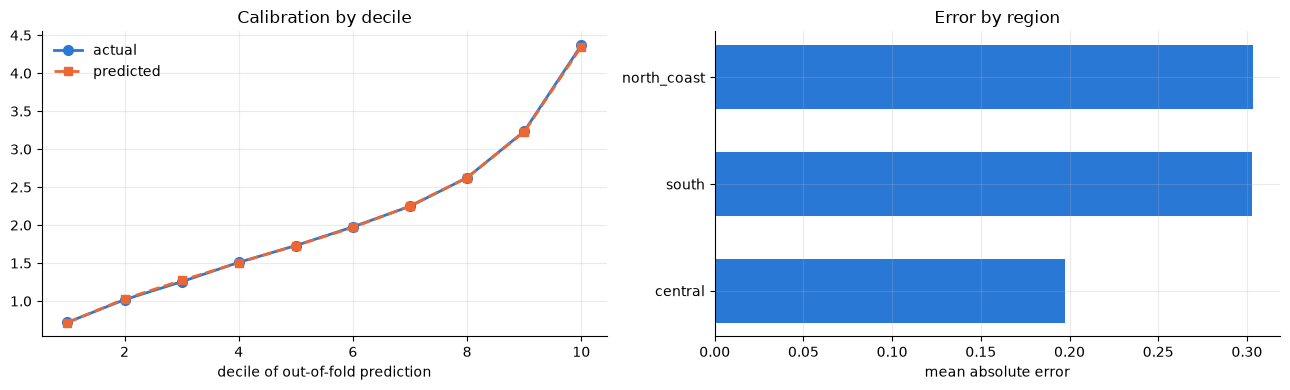

In [15]:
from sklearn.model_selection import cross_val_predict
from sklearn.inspection import permutation_importance

best_name = "LightGBM"
best_model, Xb = models[best_name]
oof = cross_val_predict(best_model, Xb, y, cv=cv, groups=groups) if TASK == "regression" else \
      cross_val_predict(best_model, Xb, y, cv=cv, groups=groups, method="predict_proba")[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dec = pd.qcut(oof, 10, labels=False, duplicates="drop")
calib = pd.DataFrame({"pred": oof, "actual": y.values if TASK == "regression" else y.astype("category").cat.codes.values}).groupby(dec).mean()
axes[0].plot(calib.index + 1, calib["actual"], "o-", color=PALETTE[0], ms=7, label="actual")
axes[0].plot(calib.index + 1, calib["pred"], "s--", color=PALETTE[1], ms=6, label="predicted")
axes[0].set_xlabel("decile of out-of-fold prediction"); axes[0].legend(); axes[0].set_title("Calibration by decile")

seg_col = next((c for c in FEATURES if not pd.api.types.is_numeric_dtype(X[c])), None)
if TASK == "regression" and seg_col:
    err = pd.Series(np.abs(y.values - oof), index=X.index).groupby(X[seg_col]).mean().sort_values()
    axes[1].barh(err.index.astype(str), err.values, color=PALETTE[0], height=0.6)
    axes[1].set_xlabel("mean absolute error"); axes[1].set_title(f"Error by {seg_col}")
else:
    axes[1].axis("off")
plt.tight_layout()
plt.show()

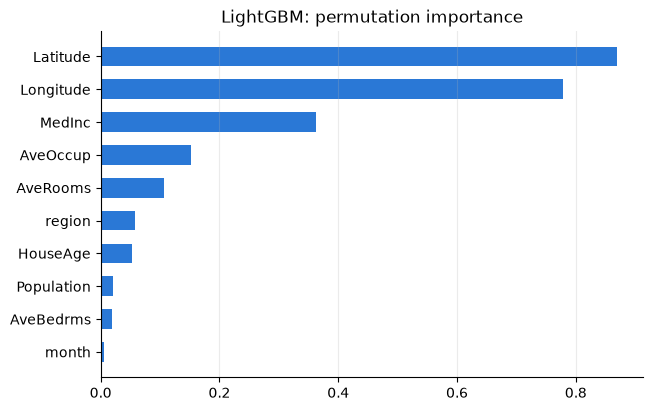

In [16]:
fitted = best_model.fit(Xb, y)
sample = Xb.sample(min(3000, len(Xb)), random_state=SEED)
pi = permutation_importance(fitted, sample, y.loc[sample.index], n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=Xb.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color=PALETTE[0], height=0.6); ax.set_title(f"{best_name}: permutation importance"); ax.grid(axis="y", visible=False)
plt.show()

For direction and interactions, add SHAP (notebook 12) for the top 2–3 features. One clear dependence plot beats a wall of charts.

## 9. Presentation skeleton (~10–15 min)

1. **Problem and answer up front**: what we predicted, how well (vs baseline), and the one-line takeaway.
2. **The data**: size, period, unit of observation; the issues found and how each was handled (read out `ISSUES` / `CLEANING_LOG`).
3. **Validation**: which split and *why* it matches deployment; what leakage you guarded against.
4. **Results**: baseline → linear → boosting table with fold sd; why you chose the final model.
5. **What drives it**: 2–3 features with plots; does it make domain sense?
6. **Where it fails**: segments/deciles with large errors; known limitations.
7. **Next steps**: what you'd do with another day/week (more data, features, monitoring, tuning, ensembling).

**Tips:** state assumptions out loud; show one thing you tried that *didn't* work and what it taught you; round numbers; label every axis; keep a backup slide with the full CV table. For the closing interview, expect "what would you do differently?", "how would you deploy/monitor this?", and "what if this feature isn't available in production?"

In [17]:
print("ISSUES FOUND"); [print(f"  {i}. {s}") for i, s in enumerate(ISSUES, 1)]
print("\nCLEANING LOG"); [print(f"  - {s}") for s in CLEANING_LOG]
print("\nRESULTS"); print(board.round(4).to_string())

ISSUES FOUND
  1. `HouseAge`: missing, piles up at min/max (cap?)
  2. `AveRooms`: sentinel? [-999.0]
  3. `price`: piles up at min/max (cap?)
  4. `data_source`: constant
  5. 150 fully duplicated rows
  6. 150 repeated values of ID column `listing_id`
  7. target is capped: 4.7% of rows sit exactly at the max (5.000)
  8. `appraisal_value` alone explains almost everything (strength 1.00): leakage suspect

CLEANING LOG
  - dropped 150 duplicated rows
  - `AveRooms`: 112 sentinel values [-999.0] -> NaN
  - dropped constant columns ['data_source']
  - dropped leakage suspects ['appraisal_value'] (confirm on the call!)

RESULTS
                 rmse mean  r2 mean  rmse sd   r2 sd
baseline (mean)     1.1539   0.0000   0.0081  0.0000
Ridge               0.7199   0.6106   0.0071  0.0126
LightGBM            0.4468   0.8501   0.0058  0.0031
